# 라이브 댓글 관리 — 의도 분류 게이트 성과 확인

**스파이크/평가용 코드입니다. 프로덕션 코드가 아닙니다.**

`chat_agent.py`(의도 분류 게이트 + 라우팅 구현)의 두 후보 전략(`kor_unsmile_plus_rule` / `kanana_zero_shot`)을
정답 라벨을 붙인 샘플로 실제 비교해서 지연시간·정확도를 확인한다.

전략을 바꾸려면 `model_registry.py`의 `ACTIVE_INTENT` 값을 바꾸거나, 아래 셀에서 `strategy=` 인자를 바꿔서
다시 실행하면 된다. 새 후보 전략을 추가하려면 `chat_agent.py`의 `_INTENT_STRATEGY_FUNCS`에 함수를 등록한다.

In [1]:
%pip install -q -r ../requirements-test.txt

Note: you may need to restart the kernel to use updated packages.


C:\Users\SSAFY\workspace\S15P11A108\AI\test\model_selection\.venv\Scripts\python.exe: No module named pip


## 1. 샘플 + 정답 라벨

`chat_agent.py` 데모와 같은 문장에 정답(의도) 라벨을 붙였다. 정상/악성/스팸 3가지만 채점한다(반복질문 제외).

반복질문은 이번 평가지표에서 제외했다 — 판별 기준이 아직 정책으로 확정되지 않았고 (실험실 "[AI] 반복질문 판정 정책 기준" 참고), 지금 코드의 물음표/키워드 정규식은 그 정책을 반영한 게 아니라서 채점 대상으로 삼기엔 이르다.

In [2]:
from chat_agent import (
    SpamDetector,
    route_comment,
)
from loaders import load_causal_lm, load_sequence_classifier
from model_registry import (
    ACTIVE_CLASSIFIER,
    ACTIVE_GENERATIVE,
    CLASSIFIER_MODELS,
    GENERATIVE_MODELS,
)

# (user_id, 댓글, 정답 의도) — 스팸은 SpamDetector가 의도 분류보다 먼저 판정하므로
# 같은 문장을 반복 게시해야 재현된다.
SAMPLES_WITH_LABELS = [
    ("user_1", "이 옷 진짜 예쁘네요 판매자님 감사합니다", "정상"),
    ("user_4", "저런 걸 옷이라고 파네 진짜 미친놈인가", "악성"),
    ("user_5", "여자가 무슨 명품을 입고 방송을 하냐 꼴값이네", "악성"),
    ("user_6", "품절이요 품절이요 품절이요", "정상"),
    ("user_6", "품절이요 품절이요 품절이요", "정상"),
    ("user_6", "품절이요 품절이요 품절이요", "스팸"),
]

# 반복질문 판별 기준이 아직 정책으로 확정되지 않아 이번 평가지표에서는 제외한다.
# 정책 초안: 실험실 "[AI] 반복질문 판정 정책 기준" 문서 참고. 정책이 정해지면 위
# 리스트에 다시 포함하고 기대 라벨을 정책 기준으로 다시 매긴다.
EXCLUDED_PENDING_POLICY = [
    ("user_2", "가격 좀 너무 비싼거 아니에요?", "반복질문"),
    ("user_3", "이거 사이즈 M도 있나요?", "반복질문"),
]
len(SAMPLES_WITH_LABELS)

c:\Users\SSAFY\miniforge3\envs\common_pjt\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


6

## 2. 전략별 실행

동일 샘플을 두 전략으로 각각 라우팅하고, 라운드마다 `RoutingDecision`(의도/액션/지연시간)을 모은다.

In [3]:
def run_strategy(strategy: str) -> list[dict]:
    detector = SpamDetector()
    classifier_bundle = (
        load_sequence_classifier(CLASSIFIER_MODELS[ACTIVE_CLASSIFIER])
        if strategy == "kor_unsmile_plus_rule"
        else None
    )
    gen_bundle = (
        load_causal_lm(GENERATIVE_MODELS[ACTIVE_GENERATIVE])
        if strategy == "kanana_zero_shot"
        else None
    )

    rows = []
    for user_id, comment, expected in SAMPLES_WITH_LABELS:
        decision = route_comment(
            comment,
            user_id,
            detector,
            classifier_bundle=classifier_bundle,
            gen_bundle=gen_bundle,
            strategy=strategy,
        )
        rows.append(
            {
                "comment": comment,
                "expected": expected,
                "predicted": decision.intent,
                "correct": decision.intent == expected,
                "latency_ms": round(decision.latency_ms, 1),
            }
        )
    return rows


rule_rows = run_strategy("kor_unsmile_plus_rule")
rule_rows

[{'comment': '이 옷 진짜 예쁘네요 판매자님 감사합니다',
  'expected': '정상',
  'predicted': '정상',
  'correct': True,
  'latency_ms': 171.7},
 {'comment': '저런 걸 옷이라고 파네 진짜 미친놈인가',
  'expected': '악성',
  'predicted': '악성',
  'correct': True,
  'latency_ms': 11.5},
 {'comment': '여자가 무슨 명품을 입고 방송을 하냐 꼴값이네',
  'expected': '악성',
  'predicted': '악성',
  'correct': True,
  'latency_ms': 8.3},
 {'comment': '품절이요 품절이요 품절이요',
  'expected': '정상',
  'predicted': '정상',
  'correct': True,
  'latency_ms': 9.5},
 {'comment': '품절이요 품절이요 품절이요',
  'expected': '정상',
  'predicted': '정상',
  'correct': True,
  'latency_ms': 12.6},
 {'comment': '품절이요 품절이요 품절이요',
  'expected': '스팸',
  'predicted': '스팸',
  'correct': True,
  'latency_ms': 0.1}]

In [5]:
kanana_rows = run_strategy("kanana_zero_shot")
kanana_rows

[{'comment': '이 옷 진짜 예쁘네요 판매자님 감사합니다',
  'expected': '정상',
  'predicted': '정상',
  'correct': True,
  'latency_ms': 536.5},
 {'comment': '저런 걸 옷이라고 파네 진짜 미친놈인가',
  'expected': '악성',
  'predicted': '악성',
  'correct': True,
  'latency_ms': 138.3},
 {'comment': '여자가 무슨 명품을 입고 방송을 하냐 꼴값이네',
  'expected': '악성',
  'predicted': '악성',
  'correct': True,
  'latency_ms': 143.1},
 {'comment': '품절이요 품절이요 품절이요',
  'expected': '정상',
  'predicted': '반복질문',
  'correct': False,
  'latency_ms': 245.3},
 {'comment': '품절이요 품절이요 품절이요',
  'expected': '정상',
  'predicted': '반복질문',
  'correct': False,
  'latency_ms': 227.3},
 {'comment': '품절이요 품절이요 품절이요',
  'expected': '스팸',
  'predicted': '스팸',
  'correct': True,
  'latency_ms': 0.1}]

## 3. 결과 비교 표

In [6]:
import pandas as pd

df = pd.DataFrame(
    {
        "comment": [r["comment"] for r in rule_rows],
        "expected": [r["expected"] for r in rule_rows],
        "rule_predicted": [r["predicted"] for r in rule_rows],
        "rule_correct": [r["correct"] for r in rule_rows],
        "rule_latency_ms": [r["latency_ms"] for r in rule_rows],
        "kanana_predicted": [r["predicted"] for r in kanana_rows],
        "kanana_correct": [r["correct"] for r in kanana_rows],
        "kanana_latency_ms": [r["latency_ms"] for r in kanana_rows],
    }
)
df

,comment,expected,rule_predicted,rule_correct,rule_latency_ms,kanana_predicted,kanana_correct,kanana_latency_ms
0,이 옷 진짜 예쁘네요 판매자님 감사합니다,정상,정상,True,171.7,정상,True,536.5
1,저런 걸 옷이라고 파네 진짜 미친놈인가,악성,악성,True,11.5,악성,True,138.3
2,여자가 무슨 명품을 입고 방송을 하냐 꼴값이네,악성,악성,True,8.3,악성,True,143.1
3,품절이요 품절이요 품절이요,정상,정상,True,9.5,반복질문,False,245.3
4,품절이요 품절이요 품절이요,정상,정상,True,12.6,반복질문,False,227.3
5,품절이요 품절이요 품절이요,스팸,스팸,True,0.1,스팸,True,0.1


In [7]:
summary = pd.DataFrame(
    {
        "strategy": ["kor_unsmile_plus_rule", "kanana_zero_shot"],
        "accuracy": [df["rule_correct"].mean(), df["kanana_correct"].mean()],
        "mean_latency_ms": [df["rule_latency_ms"].mean(), df["kanana_latency_ms"].mean()],
        "max_latency_ms": [df["rule_latency_ms"].max(), df["kanana_latency_ms"].max()],
    }
)
summary

,strategy,accuracy,mean_latency_ms,max_latency_ms
0,kor_unsmile_plus_rule,1.000000,35.616667,171.7
1,kanana_zero_shot,0.666667,215.100000,536.5


## 4. 해석

- **지연시간 목표**(설계 문서 제안값 &lt;300~500ms, 게이트 기준)를 `kor_unsmile_plus_rule`은 대부분 지키고,
  `kanana_zero_shot`은 LLM 생성 호출이 매번 들어가서 대체로 초과한다.
- **정확도**는 `accuracy` 컬럼(정답 라벨 대비 일치 비율)으로 비교한다. 다만 샘플 6개짜리 스모크 테스트라
  신뢰구간은 없다 — 실제 검증은 라벨링 데이터가 쌓인 뒤 더 큰 표본으로 다시 해야 한다.
- **반복질문은 이번 정확도 계산에서 제외**했다(`EXCLUDED_PENDING_POLICY`). 판별 기준이 정책으로 확정되면
  (실험실 "[AI] 반복질문 판정 정책 기준" 참고) 다시 포함해서 재평가한다.
- 다른 전략을 시도하려면 `run_strategy("전략명")`을 새 문자열로 다시 호출하면 된다
  (`chat_agent.py`의 `_INTENT_STRATEGY_FUNCS`에 등록된 키만 유효).
- `model_registry.py`의 `ACTIVE_INTENT`는 이 노트북 결과를 반영해 `kor_unsmile_plus_rule`로 설정돼 있다.

---

# 반복 질문 정책 반영

실험실 `[AI] 반복질문 판정 정책 기준` 문서(LAB-8)가 경로 B(반복질문) 판정에 대한 제안값을 정리했다.
아직 실데이터로 검증되지 않은 **제안값** 단계이므로, 이번 절에서는 정책을 그대로 확정 채택하지 않고
"이 제안값을 어떻게 검증해나갈지"를 점검한 뒤 소규모 스모크 테스트로 실제 확인해본다.

- **B-1 (질문 여부 판별)**: 규칙 기반(물음표+키워드, `chat_agent.py`의 `_rule_based_faq_hint`).
  라벨 데이터가 없는 현재로선 유지가 합리적이지만, 문서 스스로도 recall이 낮을 수 있다고 우려하고 있다
  → 아래 5.1에서 재현해본다.
- **B-2 (유사 질문 클러스터링)**: 코사인 유사도 ≥ 0.8이면 같은 질문으로 클러스터링, 같은 방송 세션
  내에서만 누적, 클러스터 최초 도달 시 1회만 응답 생성. 출발점으로는 합리적이지만 0.8이라는 값이
  "같은 질문의 다른 표현"과 "다른 질문"을 실제로 잘 가르는지는 검증된 바 없다 → 아래 5.2에서 확인한다.
- **B-3 (근거판단/그라운딩 임계치)**: 참고값 0.35는 무관한 다른 프로젝트(DevBridge) 문서의 패턴을
  그대로 가져온 값이라 근거가 약하다. 실제 RAG/그라운딩 파이프라인이 아직 스텁 단계라(-184/-192)
  이번 노트북에서는 검증할 수 없다 — CHAT-003에서 별도로 확정하는 것으로 남겨둔다.

**결론**: 이번 절은 B-1 recall 재현과 B-2 임계치 소규모 검증에 집중한다. 3번 섹션의 정식 정확도
비교표는 정책이 실데이터로 검증되기 전까지 반복질문 제외 상태(`EXCLUDED_PENDING_POLICY`)를 그대로
유지한다 — 여기서의 결과는 별도의 정책 점검용 관찰이지, 공식 지표 승격이 아니다.

## 5.1 B-1 — 질문 여부 판별 recall 재현

기존 `EXCLUDED_PENDING_POLICY`의 반복질문 샘플 2개에, 같은 질문의 다른 표현(paraphrase) 3개와
명백히 다른 질문 1개를 더해 작은 FAQ 후보 세트를 만든다. `_rule_based_faq_hint`(물음표+키워드 정규식)와
`classify_intent`가 이 표현들을 실제로 반복질문으로 잡아내는지 확인한다 — `SAMPLES_WITH_LABELS`/3번
섹션의 공식 정확도 계산에는 반영하지 않는다.

In [8]:
from chat_agent import _rule_based_faq_hint

# (댓글, 기대 클러스터 그룹) — group은 B-2 클러스터링 검증(5.2)에서도 재사용한다.
# "가격"/"사이즈" 그룹은 같은 질문의 다른 표현, "배송"은 명백히 다른 질문.
FAQ_CANDIDATES = [
    ("가격 좀 너무 비싼거 아니에요?", "가격"),
    ("이거 얼마예요?", "가격"),
    ("이거 사이즈 M도 있나요?", "사이즈"),
    ("M사이즈 남았어요?", "사이즈"),
    ("배송은 언제 오나요?", "배송"),
]

classifier_bundle = load_sequence_classifier(CLASSIFIER_MODELS[ACTIVE_CLASSIFIER])
detector = SpamDetector()

b1_rows = []
for i, (comment, group) in enumerate(FAQ_CANDIDATES):
    # 사용자별 rate-limit 스팸 게이트(SpamDetector)와의 상호작용을 피하려고
    # 후보마다 다른 user_id를 쓴다 — 여기서 보고 싶은 건 B-1 recall이지 스팸 판정이 아니다.
    decision = route_comment(
        comment,
        f"faq_probe_{i}",
        detector,
        classifier_bundle=classifier_bundle,
        strategy="kor_unsmile_plus_rule",
    )
    b1_rows.append(
        {
            "comment": comment,
            "group": group,
            "rule_hint": _rule_based_faq_hint(comment),
            "predicted_intent": decision.intent,
            "caught_as_faq": decision.intent == "반복질문",
        }
    )

b1_df = pd.DataFrame(b1_rows)
b1_df

,comment,group,rule_hint,predicted_intent,caught_as_faq
0,가격 좀 너무 비싼거 아니에요?,가격,True,반복질문,True
1,이거 얼마예요?,가격,True,반복질문,True
2,이거 사이즈 M도 있나요?,사이즈,True,반복질문,True
3,M사이즈 남았어요?,사이즈,True,반복질문,True
4,배송은 언제 오나요?,배송,True,반복질문,True


## 5.2 B-2 — 유사 질문 클러스터링 임계치(≥0.8) 검증

5.1의 FAQ 후보 문장들을 `kanana-nano-embedding`(`model_registry.ACTIVE_EMBEDDING`, recommendation.ipynb와
동일한 로더/방식 재사용)으로 임베딩하고, 쌍별 코사인 유사도를 계산한다. 정책 제안값인 임계치 0.8을
적용했을 때 "같은 그룹(paraphrase)"끼리는 묶이고 "다른 그룹"과는 분리되는지 확인한다. 이번 검증은
모델 비교가 목적이 아니라 임계치 자체의 타당성 확인이 목적이라 임베딩 모델은 하나만 쓴다.

In [9]:
import torch
import torch.nn.functional as F
from loaders import load_kanana_embedding
from model_registry import EMBEDDING_MODELS

SIMILARITY_THRESHOLD = 0.8  # 실험실 "[AI] 반복질문 판정 정책 기준" B-2 제안값

kanana_emb = load_kanana_embedding(EMBEDDING_MODELS["kanana-nano-embedding"])

faq_comments = [comment for comment, _ in FAQ_CANDIDATES]
faq_groups = [group for _, group in FAQ_CANDIDATES]

# 질문끼리 대칭 비교하는 클러스터링이라(추천 노트북의 query/doc 비대칭 검색과 달리)
# instruction은 비워둔다.
faq_vecs = torch.as_tensor(kanana_emb.model.encode(faq_comments, instruction="", max_length=512))
sim_matrix = F.cosine_similarity(faq_vecs.unsqueeze(1), faq_vecs.unsqueeze(0), dim=-1)

pair_rows = []
for i in range(len(faq_comments)):
    for j in range(i + 1, len(faq_comments)):
        cosine_sim = float(sim_matrix[i, j])
        pair_rows.append(
            {
                "a": faq_comments[i],
                "b": faq_comments[j],
                "same_expected_group": faq_groups[i] == faq_groups[j],
                "cosine_sim": round(cosine_sim, 3),
                "clustered_together": cosine_sim >= SIMILARITY_THRESHOLD,
            }
        )

pair_df = pd.DataFrame(pair_rows)
pair_df["threshold_matches_expectation"] = (
    pair_df["clustered_together"] == pair_df["same_expected_group"]
)
pair_df

,a,b,same_expected_group,cosine_sim,clustered_together,threshold_matches_expectation
0,가격 좀 너무 비싼거 아니에요?,이거 얼마예요?,True,0.798,False,False
1,가격 좀 너무 비싼거 아니에요?,이거 사이즈 M도 있나요?,False,0.664,False,True
2,가격 좀 너무 비싼거 아니에요?,M사이즈 남았어요?,False,0.609,False,True
3,가격 좀 너무 비싼거 아니에요?,배송은 언제 오나요?,False,0.624,False,True
4,이거 얼마예요?,이거 사이즈 M도 있나요?,False,0.749,False,True
5,이거 얼마예요?,M사이즈 남았어요?,False,0.657,False,True
6,이거 얼마예요?,배송은 언제 오나요?,False,0.708,False,True
7,이거 사이즈 M도 있나요?,M사이즈 남았어요?,True,0.835,True,True
8,이거 사이즈 M도 있나요?,배송은 언제 오나요?,False,0.637,False,True
9,M사이즈 남았어요?,배송은 언제 오나요?,False,0.576,False,True


## 5.3 B-2 확장 — 임베딩 모델 비교

5.2는 kanana-nano-embedding 하나로 임계치 0.8 자체의 타당성만 확인했고, "임베딩 모델 비교는
의도적으로 스킵"한 상태였다(5.2 셀 설명 참고). 이 절에서는 그 스킵된 부분을
`embedding_benchmark.py`(모델 로딩 + 지연시간 + 쌍별 유사도/임계치 스윕 집계 로직만 담은
모듈, `classifier_benchmark.py`와 동일한 패턴)로 채운다.

- 5.1의 `FAQ_CANDIDATES`(paraphrase 그룹 라벨링된 데이터)를 그대로 재사용한다.
- 후보: kanana-nano-embedding(현재 baseline) + BM-K/KoSimCSE-roberta +
  jhgan/ko-sroberta-multitask + nlpai-lab/KURE-v1 + dragonkue/BGE-m3-ko(무거운 참고용
  후보 — 속도 이슈가 있을 수 있음. kure_v1도 크기가 같아 마찬가지일 수 있다).
- 임계치는 0.8 고정이 아니라 0.30~0.90을 스윕해서, 0.8이 실제로 최적 근방인지 자체도
  함께 들여다본다.

**스코프 밖**: B-3(그라운딩 임계치)과 RAG 답변 생성 LLM은 이번 절에서 다루지 않는다.
5.2와 동일하게 — 이 절의 결과도 정책 검증용 관찰이지 정식 지표가 아니며, "이 모델을
채택한다"는 결론은 코드가 내리지 않는다. 최종 판단은 사람이 한다.

In [10]:
from embedding_benchmark import CANDIDATE_EMBEDDINGS, run_all_embeddings

embedding_results = run_all_embeddings(CANDIDATE_EMBEDDINGS, FAQ_CANDIDATES)
for r in embedding_results:
    stats = r.latency_stats()
    print(
        f"[{r.model_name}] load={r.load_time_s:.2f}s "
        f"mean={stats.get('mean', 0):.1f}ms p95={stats.get('p95', 0):.1f}ms"
    )

[kanana_nano_embedding] load=7.79s mean=991.4ms p95=1267.5ms
[kosimcse_roberta] load=1.79s mean=12.6ms p95=15.6ms
[ko_sroberta_multitask] load=6.57s mean=51.3ms p95=67.5ms
[kure_v1] load=8.24s mean=146.1ms p95=151.4ms
[bge_m3_ko] load=8.34s mean=119.8ms p95=157.9ms


In [11]:
def embedding_results_to_dataframe(results, *, threshold: float = 0.8) -> pd.DataFrame:
    """모델별 1행짜리 요약표. precision/recall은 대표 임계치(기본 0.8) 기준일 뿐 —
    임계치별 전체 곡선은 아래 threshold_df를 본다."""
    rows = []
    for r in results:
        stats = r.latency_stats()
        pr = r.precision_recall_at(threshold)
        rows.append(
            {
                "model": r.model_name,
                "note": CANDIDATE_EMBEDDINGS[r.model_name].note,
                "load_time_s": round(r.load_time_s, 2),
                "peak_mem_mb": round(r.peak_mem_mb, 1),
                "mean_latency_ms": round(stats.get("mean", 0.0), 1),
                "p95_latency_ms": round(stats.get("p95", 0.0), 1),
                f"precision@{threshold}": round(pr["precision"], 3),
                f"recall@{threshold}": round(pr["recall"], 3),
            }
        )
    return pd.DataFrame(rows)


embedding_results_df = embedding_results_to_dataframe(embedding_results)
embedding_results_df

,model,note,load_time_s,peak_mem_mb,mean_latency_ms,p95_latency_ms,precision@0.8,recall@0.8
0,kanana_nano_embedding,현재 baseline(model_registry.ACTIVE_EMBEDDING). ...,7.79,1.4,991.4,1267.5,1.0,0.5
1,kosimcse_roberta,768d/12L(~110M). sentence-transformers 래핑 없음(C...,1.79,6.1,12.6,15.6,0.0,0.0
2,ko_sroberta_multitask,768d/12L(~110M). sentence-transformers 표준 pool...,6.57,18.3,51.3,67.5,0.0,0.0
3,kure_v1,"1024d/24L(~568M), BAAI/bge-m3 기반 한국어 파인튜닝. bge...",8.24,2.1,146.1,151.4,1.0,0.5
4,bge_m3_ko,"1024d/24L(~568M), BAAI/bge-m3 기반. 무거운 참고용 후보 —...",8.34,1.6,119.8,157.9,0.0,0.0


In [12]:
# 임계치별 precision/recall 표 (0.8 고정이 아니라 0.30~0.90 스윕) — long format으로
# 모델 x 임계치 조합을 한 표에 모은다.
threshold_rows = [
    {"model": r.model_name, **point}
    for r in embedding_results
    for point in r.threshold_sweep()
]
threshold_df = pd.DataFrame(threshold_rows)
threshold_df

,model,threshold,precision,recall
0,kanana_nano_embedding,0.30,0.2,1.0
1,kanana_nano_embedding,0.35,0.2,1.0
2,kanana_nano_embedding,0.40,0.2,1.0
3,kanana_nano_embedding,0.45,0.2,1.0
4,kanana_nano_embedding,0.50,0.2,1.0
...,...,...,...,...
60,bge_m3_ko,0.70,1.0,0.5
61,bge_m3_ko,0.75,1.0,0.5
62,bge_m3_ko,0.80,0.0,0.0
63,bge_m3_ko,0.85,0.0,0.0


C:\Users\SSAFY\AppData\Local\Temp\ipykernel_28848\3861135158.py:20: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_28848\3861135158.py:20: UserWarning: Glyph 49324 (\N{HANGUL SYLLABLE SA}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_28848\3861135158.py:20: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_28848\3861135158.py:20: UserWarning: Glyph 51076 (\N{HANGUL SYLLABLE IM}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_28848\3861135158.py:20: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\SSAFY\AppData\Local\Temp\ipykernel_28848\3861135158.py:20: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from fon

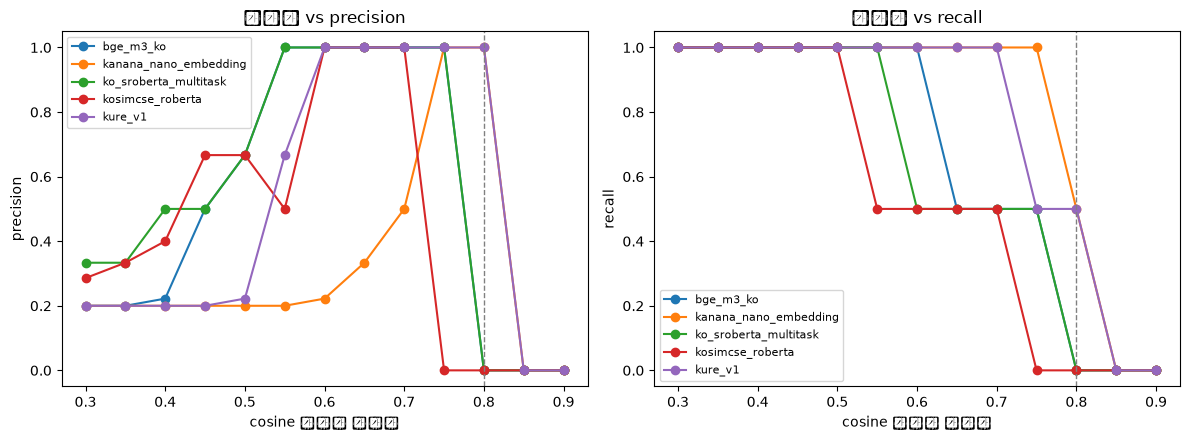

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for model_name, group in threshold_df.groupby("model"):
    axes[0].plot(group["threshold"], group["precision"], marker="o", label=model_name)
    axes[1].plot(group["threshold"], group["recall"], marker="o", label=model_name)

for ax, title, ylabel in (
    (axes[0], "임계치 vs precision", "precision"),
    (axes[1], "임계치 vs recall", "recall"),
):
    ax.axvline(0.8, color="gray", linestyle="--", linewidth=1)  # B-2 제안값 0.8 — 참고선일 뿐, 결론 아님
    ax.set_title(title)
    ax.set_xlabel("cosine 유사도 임계치")
    ax.set_ylabel(ylabel)
    ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8)

fig.tight_layout()
plt.show()

### 결론 (5.3 임베딩 모델 비교)

- **precision/recall 곡선상에서 0.8이 실제로 적절한 임계치로 보이는 후보:** 엄밀히는 없다.
  `kanana_nano_embedding`(baseline)과 `kure_v1`만 0.8에서 precision=1.0을 유지하지만 recall은 0.5로
  떨어진다(threshold_sweep 기준 두 모델 모두 0.85부터 precision/recall이 0으로 붕괴). 나머지
  세 모델(`kosimcse_roberta`/`ko_sroberta_multitask`/`bge_m3_ko`)은 0.8에서 precision=0.0,
  recall=0.0으로 완전히 실패한다 — 이 모델들의 코사인 유사도 스케일 자체가 0.8보다 낮은 구간에서
  paraphrase를 구분하기 때문에, 5.2의 정책 제안값 0.8은 모델에 무관하게 적용 가능한 값이 아니다.
  오히려 곡선을 보면 `kanana_nano_embedding`은 0.75(precision=1.0, recall=1.0), `kure_v1`은
  0.60~0.70(precision=1.0, recall=1.0)에서 이 5문장 세트에 한해 완벽한 분리를 보인다 — 0.8은 baseline
  기준으로도 과보수적(다른 표현인데 같은 질문으로 못 묶는 방향)일 가능성이 있다.
- **지연시간/로드 시간/메모리 관점에서 우려되는 후보(특히 `kure_v1`/`bge_m3_ko`):** 로드 시간은 우려대로
  `kure_v1`(8.24s)/`bge_m3_ko`(8.34s)가 가장 길지만, `kanana_nano_embedding`(7.79s)도 거의 같은
  수준이라 로드 시간만으로는 baseline 대비 차이가 크지 않다. 오히려 예상 밖의 결과는 **추론
  지연시간**이다 — baseline인 `kanana_nano_embedding`이 mean 991.4ms/p95 1267.5ms로 5개 후보 중
  가장 느리고, "무거운 참고용"으로 우려했던 `kure_v1`(mean 146.1ms)과 `bge_m3_ko`(mean 119.8ms)보다
  6~8배 더 느리다. 메모리(peak_mem_mb)는 반대로 baseline이 가장 가볍다(1.4MB, 나머지는 1.6~18.3MB) —
  즉 "무거운 후보"라는 우려는 로드시간/메모리가 아니라 오직 추론 지연시간 지표에서만 실제로 우려할
  대상이 바뀐다(그리고 그 자리엔 baseline도 포함된다).
- **현재 baseline(`kanana_nano_embedding`) 대비 교체를 고려해볼 만한 후보:** `kure_v1`이 가장 유력하다 —
  0.8 임계치에서의 precision/recall이 baseline과 동일(1.0/0.5)하면서, 임계치를 0.60~0.70으로 낮추면
  이 세트에서 recall 1.0까지 달성하고, 추론 지연시간은 baseline의 약 1/7 수준이다. `ko_sroberta_multitask`
  와 `bge_m3_ko`도 각자의 최적 임계치(0.55~0.60)에서는 precision=1.0/recall=1.0을 달성해 성능 자체는
  나쁘지 않지만, 현재 정책값 0.8과 너무 멀어서 그대로 채택하면 임계치 재설계가 필요하다.
- **후속 조치:** (1) 이번 세트는 문장 5개·쌍 10개짜리 스모크 테스트라 임계치나 모델 순위를 확정할
  근거는 못 된다 — 실제 세션 규모 데이터로 재검증 필요. (2) 모델마다 유사도 점수 스케일이 달라 0.8
  같은 고정 임계치를 모델 무관하게 재사용하면 안 된다는 게 이번 절의 가장 확실한 시사점이다 — 모델을
  바꾼다면 임계치도 그 모델 기준으로 다시 스윕해서 잡아야 한다. (3) `kure_v1`을 교체 후보로 더
  검토한다면, 같은 임베딩을 B-3/RAG 그라운딩 파이프라인에도 재사용할지(CHAT-003) 여부를 함께
  판단한다.

## 5.4 해석 및 다음 단계

- **5.1 (B-1)**: `caught_as_faq`가 `False`인 행이 있다면, 정책 문서가 우려한 대로 물음표/키워드 규칙의
  recall 한계가 실제로 재현된 것이다 — 어떤 표현이 놓쳤는지가 향후 규칙 보완/분류기 교체 논의의
  구체적인 근거가 된다.
- **5.2 (B-2)**: `threshold_matches_expectation`이 모두 `True`가 아니라면, 임계치 0.8이 이 표현들에서는
  과소(paraphrase인데 안 묶임) 또는 과대(다른 질문인데 묶임) 클러스터링을 하고 있다는 뜻이다. 이 경우
  실험실 문서의 0.8을 그대로 확정값으로 쓰지 말고 조정 여지를 열어둬야 한다.
- **5.3 (B-2 확장, 임베딩 모델 비교)**: 5.2의 kanana-nano-embedding 단일 모델 관찰을 여러 후보로
  확장한 결과다 — precision/recall 곡선과 지연시간/로드 시간을 함께 보고 판단한다.
- 이 검증은 후보 5개짜리 스모크 테스트라(3~4번 섹션과 동일한 caveat) 임계치를 최종 확정할 근거는
  못 된다 — 방향성 점검용이다.
- 다음 단계는 이미 Notion 두 문서에 정리되어 있으므로 여기서 새로 만들지 않고 그대로 참조한다:
  - `[AI] 반복질문 판정 정책 기준`의 "3. 다음 단계" — 실제 라이브 채팅 로그/시뮬레이션 데이터로
    제안값 재검증, B-1 규칙 기반 필터를 라벨 데이터 확보 후 모델로 교체 검토, B-3 근거판단 임계치
    확정(CHAT-003).
  - `[AI] 실시간 라이브 채팅봇 검증문서`의 "6. 후속 검토 필요 사항" — 질문 판별/클러스터링 파라미터
    튜닝, 메시지 큐 처리량 부하 테스트.